In [2]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/T3_MRI_Denoising")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/T3_MRI_Denoising


In [4]:
from pathlib import Path
import subprocess

CODE_DIR = Path("/content/NGPS")

if not CODE_DIR.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/cv-cho/NGPS.git", str(CODE_DIR)],
        check=True
    )

print("Code version:")
subprocess.run(["git", "-C", str(CODE_DIR), "rev-parse", "HEAD"], check=True)

print("\nRequired packages:")
requirements = CODE_DIR / "requirements.txt"
print(requirements.read_text() if requirements.exists()
      else "No requirements.txt found.")

Code version:

Required packages:
numpy>=1.23
scipy>=1.9
opencv-python>=4.7
scikit-image>=0.20
torch>=2.0
tqdm>=4.64
PyYAML>=6.0



In [5]:
%pip install -q "numpy>=1.23" "scipy>=1.9" "opencv-python>=4.7" "scikit-image>=0.20" "tqdm>=4.64" "PyYAML>=6.0"

import numpy as np
import scipy
import cv2
import skimage
import torch
import tqdm
import yaml

print("All required packages imported successfully.")
print("GPU available:", torch.cuda.is_available())
print("Code version:", subprocess.check_output(
    ["git", "-C", str(CODE_DIR), "rev-parse", "HEAD"],
    text=True
).strip())

All required packages imported successfully.
GPU available: True
Code version: c04331d56ad6c5c8b9ea510f77359b154db57ebe


In [6]:
import json
import sys
import subprocess
from datetime import datetime, timezone

setup_log = {
    "recorded_at": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0),
    "ngps_commit": subprocess.check_output(
        ["git", "-C", str(CODE_DIR), "rev-parse", "HEAD"],
        text=True
    ).strip()
}

log_dir = PROJECT_DIR / "logs"
log_dir.mkdir(parents=True, exist_ok=True)

(log_dir / "environment.json").write_text(
    json.dumps(setup_log, indent=2)
)

(log_dir / "installed_packages.txt").write_text(
    subprocess.check_output(
        [sys.executable, "-m", "pip", "freeze"],
        text=True
    )
)

print("Setup logs saved to:", log_dir)

Setup logs saved to: /content/drive/MyDrive/T3_MRI_Denoising/logs


In [7]:
%pip install -q nibabel

import gzip
import shutil
import nibabel as nib

file_path = "/content/drive/MyDrive/T3_MRI_Denoising/refrence_source/subject04_t1w_p4.mnc.gz"

with gzip.open(file_path, "rb") as src:
    with open("/content/subject04.mnc", "wb") as dst:
        shutil.copyfileobj(src, dst)

image = nib.load("/content/subject04.mnc")

print("MRI loaded successfully!")
print("Volume dimensions:", image.shape)
print("Voxel sizes:", image.header.get_zooms())

MRI loaded successfully!
Volume dimensions: (181, 256, 256)
Voxel sizes: (1.0, 1.0, 1.0)


In [8]:
from pathlib import Path
import gzip
import shutil
import json
import nibabel as nib

PROJECT_DIR = Path("/content/drive/MyDrive/T3_MRI_Denoising")
source_dir = PROJECT_DIR / "refrence_source"

splits = {
    "train": ["04", "05", "06", "18", "20", "38"],
    "validation": ["41", "42"],
    "test": ["43", "44"]
}

manifest = []

for split, subjects in splits.items():
    for subject in subjects:
        matches = list(source_dir.glob(f"subject{subject}_t1w*.mnc.gz"))
        assert len(matches) == 1, (
            f"Subject {subject}: expected one file, found {len(matches)}"
        )

        source = matches[0]
        local = Path(f"/content/subject{subject}.mnc")

        with gzip.open(source, "rb") as src, local.open("wb") as dst:
            shutil.copyfileobj(src, dst)

        image = nib.load(str(local))
        assert image.shape == (181, 256, 256), (
            f"Unexpected dimensions for subject {subject}: {image.shape}"
        )

        manifest.append({
            "subject": subject,
            "split": split,
            "source_file": source.name,
            "shape": list(image.shape),
            "voxel_sizes": [float(v) for v in image.header.get_zooms()]
        })

        print(f"Subject {subject}: {split} — loaded successfully")

manifest_dir = PROJECT_DIR / "manifests"
manifest_dir.mkdir(exist_ok=True)

with (manifest_dir / "subjects.json").open("w") as f:
    json.dump(manifest, f, indent=2)

print("\nVerified 10 subjects. Split manifest saved.")

Subject 04: train — loaded successfully
Subject 05: train — loaded successfully
Subject 06: train — loaded successfully
Subject 18: train — loaded successfully
Subject 20: train — loaded successfully
Subject 38: train — loaded successfully
Subject 41: validation — loaded successfully
Subject 42: validation — loaded successfully
Subject 43: test — loaded successfully
Subject 44: test — loaded successfully

Verified 10 subjects. Split manifest saved.


In [9]:
import numpy as np

noisy_dir = PROJECT_DIR / "data" / "noisy"
reference_dir = PROJECT_DIR / "scoring_only" / "references"
reference_dir.mkdir(parents=True, exist_ok=True)

noise_records = []

for item in manifest:
    subject = item["subject"]
    split = item["split"]

    image = nib.load(f"/content/subject{subject}.mnc")
    reference = image.get_fdata(dtype=np.float32)

    assert np.isfinite(reference).all(), f"Invalid values: {subject}"

    minimum = float(reference.min())
    maximum = float(reference.max())
    assert maximum > minimum

    reference = (reference - minimum) / (maximum - minimum)
    np.save(reference_dir / f"subject{subject}.npy", reference)

    for sigma in [0.03, 0.06, 0.10]:
        seed = 42000 + int(subject) * 100 + round(sigma * 100)
        rng = np.random.default_rng(seed)

        noise = rng.normal(0, sigma, reference.shape).astype(np.float32)
        noisy = reference + noise

        folder = noisy_dir / f"sigma_{sigma:.2f}" / split
        folder.mkdir(parents=True, exist_ok=True)
        np.save(folder / f"subject{subject}.npy", noisy)

        noise_records.append({
            "subject": subject,
            "split": split,
            "sigma": sigma,
            "seed": seed,
            "reference_min": minimum,
            "reference_max": maximum,
            "noisy_file": str(
                (folder / f"subject{subject}.npy").relative_to(PROJECT_DIR)
            )
        })

    print(f"Subject {subject}: saved all three noise levels")

with (manifest_dir / "noise_generation.json").open("w") as f:
    json.dump(noise_records, f, indent=2)

print("\nDone: 30 noisy volumes and 10 scoring references saved.")

Subject 04: saved all three noise levels
Subject 05: saved all three noise levels
Subject 06: saved all three noise levels
Subject 18: saved all three noise levels
Subject 20: saved all three noise levels
Subject 38: saved all three noise levels
Subject 41: saved all three noise levels
Subject 42: saved all three noise levels
Subject 43: saved all three noise levels
Subject 44: saved all three noise levels

Done: 30 noisy volumes and 10 scoring references saved.


In [10]:
from pathlib import Path

CODE_DIR = Path("/content/NGPS")

for filename in [
    "datasets/volume_folder.py",
    "configs/ngps_nafnet_default.yaml"
]:
    print(f"\n--- {filename} ---")
    print((CODE_DIR / filename).read_text())


--- datasets/volume_folder.py ---
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import List, Optional

import numpy as np


@dataclass(frozen=True)
class VolumeItem:
    case_id: str
    noisy_path: Path
    clean_path: Optional[Path] = None


def list_volume_items(data_root: str | Path, split: str) -> List[VolumeItem]:
    """List volumes from DATA_ROOT/split/noisy/*.npy.

    If DATA_ROOT/split/clean contains a matching file, it is attached for
    evaluation. Clean volumes are never required for NGPS training.
    """

    root = Path(data_root)
    noisy_dir = root / split / "noisy"
    clean_dir = root / split / "clean"
    if not noisy_dir.exists():
        raise FileNotFoundError(f"No noisy directory found: {noisy_dir}")

    items = []
    for noisy_path in sorted(noisy_dir.glob("*.npy")):
        clean_path = clean_dir / noisy_path.name
        items.append(VolumeItem(noisy_path.stem, noisy_path, clean_path if clean

In [11]:
import shutil

# Preserve the original Gaussian noise values.
loader_path = CODE_DIR / "datasets/volume_folder.py"
text = loader_path.read_text()
text = text.replace(
    '"""Load a float32 volume shaped (D, H, W), clipped to [0, 1]."""',
    '"""Load a float32 volume shaped (D, H, W), without clipping."""'
)
text = text.replace("return np.clip(volume, 0.0, 1.0)", "return volume")
loader_path.write_text(text)

# Copy only training data at sigma=0.06 to Colab's local disk.
local_data = Path("/content/mri_sigma_006")
destination = local_data / "train" / "noisy"
destination.mkdir(parents=True, exist_ok=True)

source = PROJECT_DIR / "data/noisy/sigma_0.06/train"
for file in sorted(source.glob("*.npy")):
    shutil.copy2(file, destination / file.name)

assert len(list(destination.glob("*.npy"))) == 6

# Save the modified loader to Drive.
saved_loader = PROJECT_DIR / "code_changes/datasets/volume_folder.py"
saved_loader.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(loader_path, saved_loader)

print("Loader updated and saved.")
print("Six training volumes copied locally.")

# Check the training command's available options.
result = subprocess.run(
    [sys.executable, "scripts/train_ngps.py", "--help"],
    cwd=CODE_DIR,
    capture_output=True,
    text=True
)
print(result.stdout)
print(result.stderr)

Loader updated and saved.
Six training volumes copied locally.
usage: train_ngps.py [-h] --data-root DATA_ROOT [--config CONFIG]
                     [--output-dir OUTPUT_DIR] [--device DEVICE]
                     [--central-fraction CENTRAL_FRACTION]
                     [--save-every SAVE_EVERY]

Train NGPS on local .npy volumes.

options:
  -h, --help            show this help message and exit
  --data-root DATA_ROOT
  --config CONFIG
  --output-dir OUTPUT_DIR
  --device DEVICE
  --central-fraction CENTRAL_FRACTION
  --save-every SAVE_EVERY




In [12]:
import numpy as np
import yaml

# One neighboring-slice triplet from a training subject.
smoke_root = Path("/content/mri_smoke")
smoke_folder = smoke_root / "train/noisy"
smoke_folder.mkdir(parents=True, exist_ok=True)

volume = np.load(local_data / "train/noisy/subject04.npy")
np.save(smoke_folder / "subject04.npy", volume[89:92])

# Keep the model architecture; reduce the workload for this check.
config = yaml.safe_load(
    (CODE_DIR / "configs/ngps_nafnet_default.yaml").read_text()
)
config["training"].update({
    "epochs": 1,
    "batch_size": 1,
    "crop_size": 64,
    "num_workers": 0
})

config_path = PROJECT_DIR / "configs/smoke.yaml"
config_path.parent.mkdir(parents=True, exist_ok=True)
config_path.write_text(yaml.safe_dump(config))

output_dir = PROJECT_DIR / "runs/smoke_ngps"

subprocess.run(
    [
        sys.executable, "scripts/train_ngps.py",
        "--data-root", str(smoke_root),
        "--config", str(config_path),
        "--output-dir", str(output_dir),
        "--device", "cuda"
    ],
    cwd=CODE_DIR,
    check=True
)

print("GPU training check completed.")
print("Saved files:", [p.name for p in output_dir.iterdir()])

GPU training check completed.
Saved files: ['model_E1.pth', 'model_final.pth']


In [13]:
for filename in [
    "scripts/train_ngps.py",
    "datasets/triplet_dataset.py"
]:
    print(f"\n--- {filename} ---")
    print((CODE_DIR / filename).read_text())


--- scripts/train_ngps.py ---
from __future__ import annotations

import argparse
from dataclasses import asdict
from pathlib import Path
import sys

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

from datasets.triplet_dataset import VolumeTripletDataset
from datasets.volume_folder import list_volume_items
from ngps import NGPSHybridLoss, NeighborGuidedPatchSampler, build_nafnet, load_config
from ngps.seed import seed_everything


def main() -> None:
    parser = argparse.ArgumentParser(description="Train NGPS on local .npy volumes.")
    parser.add_argument("--data-root", required=True)
    parser.add_argument("--config", default="configs/ngps_nafnet_default.yaml")
    parser.add_argument("--output-dir", default="runs/ngps")
    parser.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    parser.add_argument("--central-fraction", type=float, default=1.

In [14]:
import json
import shutil
import yaml

# Save the training configuration.
config = yaml.safe_load(
    (CODE_DIR / "configs/ngps_nafnet_default.yaml").read_text()
)
config["training"].update({
    "epochs": 5,
    "batch_size": 1,
    "crop_size": 128,
    "num_workers": 0
})

config_path = PROJECT_DIR / "configs/course_training.yaml"
config_path.write_text(yaml.safe_dump(config))

# Record decisions before viewing test results.
protocol = {
    "methods": ["NGPS", "masked_pixel_blindspot", "naive_neighbor"],
    "additional_control": "NLM",
    "training_noise_levels": [0.03, 0.06, 0.10],
    "training_strategy": "One model per method, pooling all noise levels",
    "central_fraction": 0.25,
    "epochs": 5,
    "batch_size": 1,
    "crop_size": 128,
    "checkpoint_selection": "Final epoch; no clean-reference selection",
    "primary_metric": "Mean slice PSNR per subject, averaged equally "
                      "across test subjects and noise levels",
    "success_target": "NGPS PSNR >= each trained comparator; tolerance 0 dB",
    "secondary_metrics": ["SSIM (data_range=1)", "HFEN", "inference time"],
    "reference_policy": "Noise generation and scoring frozen results only"
}

(PROJECT_DIR / "manifests/evaluation_protocol.json").write_text(
    json.dumps(protocol, indent=2)
)

# Prepare local training data in the format NGPS expects.
training_root = Path("/content/mri_combined")
training_folder = training_root / "train/noisy"
training_folder.mkdir(parents=True, exist_ok=True)

for sigma in [0.03, 0.06, 0.10]:
    source = PROJECT_DIR / f"data/noisy/sigma_{sigma:.2f}/train"
    files = sorted(source.glob("*.npy"))
    assert len(files) == 6

    for file in files:
        destination = training_folder / f"sigma{sigma:.2f}_{file.name}"
        shutil.copy2(file, destination)

assert len(list(training_folder.glob("*.npy"))) == 18

print("Training configuration and evaluation plan saved.")
print("18 noisy training volumes ready: 6 subjects × 3 noise levels.")

Training configuration and evaluation plan saved.
18 noisy training volumes ready: 6 subjects × 3 noise levels.


In [15]:
import time
import subprocess
import sys

output_dir = PROJECT_DIR / "runs/ngps_combined"
output_dir.mkdir(parents=True, exist_ok=True)

command = [
    sys.executable, "-u", "scripts/train_ngps.py",
    "--data-root", str(training_root),
    "--config", str(config_path),
    "--output-dir", str(output_dir),
    "--device", "cuda",
    "--central-fraction", "0.25",
    "--save-every", "1"
]

start = time.time()

with (output_dir / "training.log").open("w") as log:
    process = subprocess.Popen(
        command,
        cwd=CODE_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    return_code = process.wait()

elapsed_minutes = (time.time() - start) / 60

if return_code != 0:
    raise RuntimeError("Training failed. Share the final error lines.")

(output_dir / "runtime_minutes.txt").write_text(
    f"{elapsed_minutes:.2f}\n"
)

print(f"\nTraining completed in {elapsed_minutes:.1f} minutes.")
print("Checkpoint:", output_dir / "model_final.pth")

Streaming output truncated to the last 5000 lines.
NGPS epoch 2/5: 100%|██████████| 792/792 [03:22<00:00,  3.91it/s, loss=0.0095]

NGPS epoch 3/5: 100%|██████████| 792/792 [03:19<00:00,  3.97it/s, loss=0.0092]

NGPS epoch 4/5: 100%|██████████| 792/792 [03:18<00:00,  3.99it/s, loss=0.0090]

NGPS epoch 5/5: 100%|██████████| 792/792 [03:19<00:00,  3.98it/s, loss=0.0090]
Saved checkpoint to /content/drive/MyDrive/T3_MRI_Denoising/runs/ngps_combined/model_final.pth

Training completed in 17.4 minutes.
Checkpoint: /content/drive/MyDrive/T3_MRI_Denoising/runs/ngps_combined/model_final.pth


In [16]:
run_dir = PROJECT_DIR / "runs/ngps_combined"

print("Saved checkpoints:")
for file in sorted(run_dir.glob("*.pth")):
    print(file.name)

runtime = run_dir / "runtime_minutes.txt"
if runtime.exists():
    print("\nTraining time:", runtime.read_text().strip(), "minutes")

print("\nEnd of training log:")
print((run_dir / "training.log").read_text()[-1500:])

Saved checkpoints:
model_E1.pth
model_E2.pth
model_E3.pth
model_E4.pth
model_E5.pth
model_final.pth

Training time: 17.39 minutes

End of training log:
NGPS epoch 5/5: 100%|██████████| 792/792 [03:19<00:00,  3.98it/s, loss=0.0090]
Saved checkpoint to /content/drive/MyDrive/T3_MRI_Denoising/runs/ngps_combined/model_final.pth



In [17]:
source = (CODE_DIR / "scripts/train_ngps.py").read_text()

# Add a choice between the two comparator methods.
anchor = '    parser.add_argument("--data-root", required=True)'
assert anchor in source
source = source.replace(
    anchor,
    anchor + '''
    parser.add_argument(
        "--method", required=True,
        choices=["naive_neighbor", "blindspot"]
    )'''
)

start = source.index("            with torch.no_grad():")
end = source.index("            optimizer.zero_grad", start)

baseline_step = '''
            if args.method == "naive_neighbor":
                # Predict neighboring slices at unchanged coordinates.
                prediction = model(raw_center)
                loss = 0.5 * (
                    torch.nn.functional.mse_loss(prediction, raw_prev)
                    + torch.nn.functional.mse_loss(prediction, raw_next)
                )

            else:
                # Hide about 1.6% of pixels on a randomly offset grid.
                # Spacing prevents hidden targets becoming replacement donors.
                mask = torch.zeros_like(raw_center, dtype=torch.bool)

                for b in range(raw_center.shape[0]):
                    row = int(torch.randint(0, 8, ()).item())
                    col = int(torch.randint(0, 8, ()).item())
                    mask[b, :, row::8, col::8] = True

                # Replace hidden pixels with an immediate neighboring pixel.
                donors = torch.roll(raw_center, shifts=1, dims=-1)
                masked_input = torch.where(mask, donors, raw_center)
                prediction = model(masked_input)

                # Score only hidden pixels against their original noisy values.
                loss = torch.nn.functional.mse_loss(
                    prediction[mask], raw_center[mask]
                )

'''

source = source[:start] + baseline_step + source[end:]
source = source.replace("loss_out.total.backward()", "loss.backward()")
source = source.replace(
    "float(loss_out.total.detach().cpu())",
    "float(loss.detach().cpu())"
)
source = source.replace(
    'desc=f"NGPS epoch',
    'desc=f"{args.method} epoch'
)
source = source.replace(
    '{"model": model.state_dict(),',
    '{"method": args.method, "model": model.state_dict(),'
)

script_path = CODE_DIR / "scripts/train_course_baseline.py"
script_path.write_text(source)

saved_script = PROJECT_DIR / "code_changes/scripts/train_course_baseline.py"
saved_script.parent.mkdir(parents=True, exist_ok=True)
saved_script.write_text(source)

# Check Python syntax.
compile(source, str(script_path), "exec")

print("Comparator training script created, checked, and saved to Drive.")

Comparator training script created, checked, and saved to Drive.


In [18]:
for method in ["naive_neighbor", "blindspot"]:
    output_dir = PROJECT_DIR / f"runs/{method}_combined"
    output_dir.mkdir(parents=True, exist_ok=True)

    command = [
        sys.executable, "-u", "scripts/train_course_baseline.py",
        "--method", method,
        "--data-root", str(training_root),
        "--config", str(config_path),
        "--output-dir", str(output_dir),
        "--device", "cuda",
        "--central-fraction", "0.25",
        "--save-every", "1"
    ]

    print(f"\nStarting {method}")
    start = time.time()

    with (output_dir / "training.log").open("w") as log:
        process = subprocess.Popen(
            command,
            cwd=CODE_DIR,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True
        )

        for line in process.stdout:
            print(line, end="")
            log.write(line)
            log.flush()

        return_code = process.wait()

    if return_code != 0:
        raise RuntimeError(
            f"{method} failed. Share the final error lines."
        )

    minutes = (time.time() - start) / 60
    (output_dir / "runtime_minutes.txt").write_text(f"{minutes:.2f}\n")

    print(f"\n{method} completed in {minutes:.1f} minutes.")

print("\nBoth comparison models finished.")

Streaming output truncated to the last 5000 lines.
blindspot epoch 1/5: 100%|██████████| 792/792 [01:17<00:00, 10.26it/s, loss=0.0089]

blindspot epoch 2/5: 100%|██████████| 792/792 [01:10<00:00, 11.29it/s, loss=0.0069]

blindspot epoch 3/5: 100%|██████████| 792/792 [01:10<00:00, 11.31it/s, loss=0.0067]

blindspot epoch 4/5: 100%|██████████| 792/792 [01:10<00:00, 11.20it/s, loss=0.0066]

blindspot epoch 5/5: 100%|██████████| 792/792 [01:09<00:00, 11.32it/s, loss=0.0064]
Saved checkpoint to /content/drive/MyDrive/T3_MRI_Denoising/runs/blindspot_combined/model_final.pth

blindspot completed in 6.8 minutes.

Both comparison models finished.


In [19]:
import json

checkpoints = {
    "NGPS": PROJECT_DIR / "runs/ngps_combined/model_final.pth",
    "naive_neighbor": PROJECT_DIR / "runs/naive_neighbor_combined/model_final.pth",
    "blindspot": PROJECT_DIR / "runs/blindspot_combined/model_final.pth"
}

for name, path in checkpoints.items():
    assert path.exists(), f"Missing checkpoint: {name}"
    print(f"{name}: final checkpoint found")

# Specify evaluation details before inspecting test results.
protocol_path = PROJECT_DIR / "manifests/evaluation_protocol.json"
protocol = json.loads(protocol_path.read_text())

protocol.update({
    "test_subjects": ["43", "44"],
    "evaluation_slices": "All 181 slices per volume",
    "psnr": "Per-slice PSNR, data_range=1; mean within each subject",
    "ssim": "Per-slice SSIM, data_range=1, window size 7; subject mean",
    "hfen": "RMSE between Laplacian-of-Gaussian filtered images, "
            "sigma=1.5 pixels, truncate=4; subject mean; lower is better",
    "prediction_postprocessing": "Clip all denoiser outputs to [0,1]",
    "noisy_control": "Original noisy input without clipping",
    "nlm": {
        "patch_size": 5,
        "patch_distance": 6,
        "h": "0.8 * known noise sigma",
        "sigma": "Known synthetic noise sigma",
        "fast_mode": True
    },
    "timing": "Denoising plus output clipping; exclude disk I/O and "
              "metric calculation; synchronize GPU before and after",
    "model_selection": "All models frozen at final epoch before test scoring"
})

protocol_path.write_text(json.dumps(protocol, indent=2))

print("\nEvaluation settings saved. No test results inspected.")

NGPS: final checkpoint found
naive_neighbor: final checkpoint found
blindspot: final checkpoint found

Evaluation settings saved. No test results inspected.


NGPS improved denoising substantially but did not outperform the strongest trained baseline under our limited training budget. Its advantage over NLM appeared at the highest noise level.

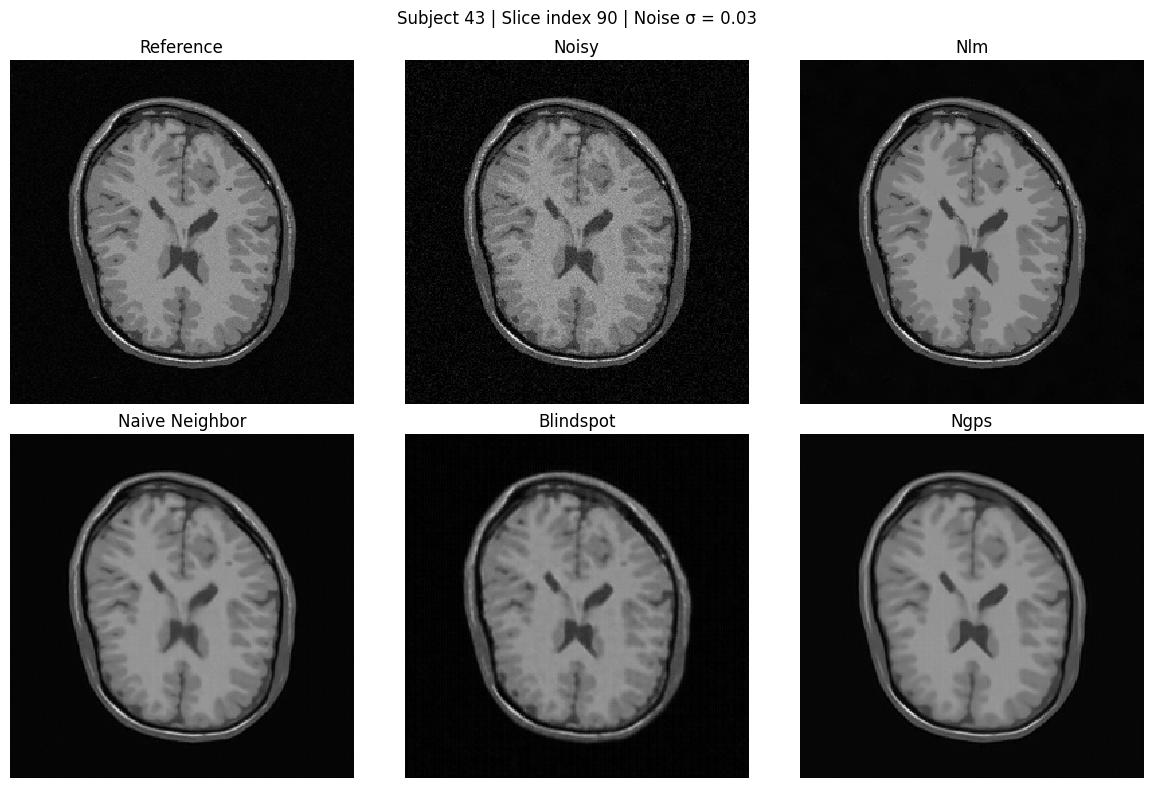

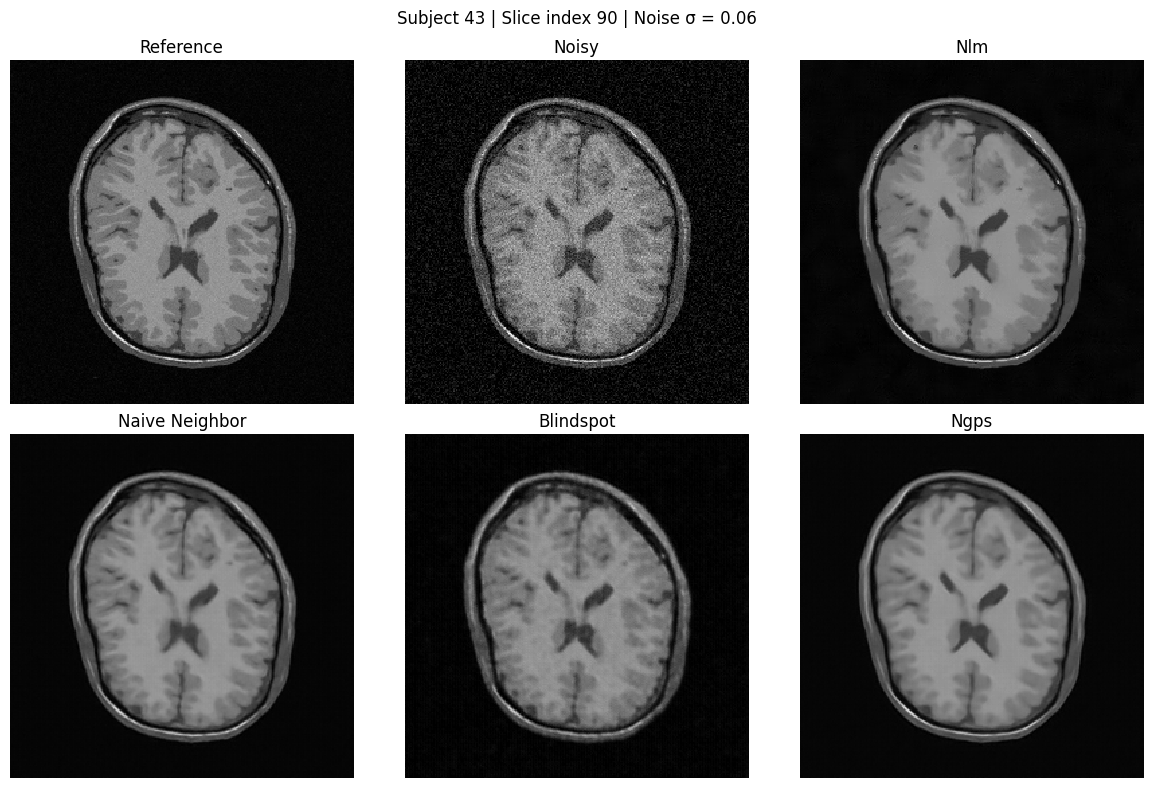

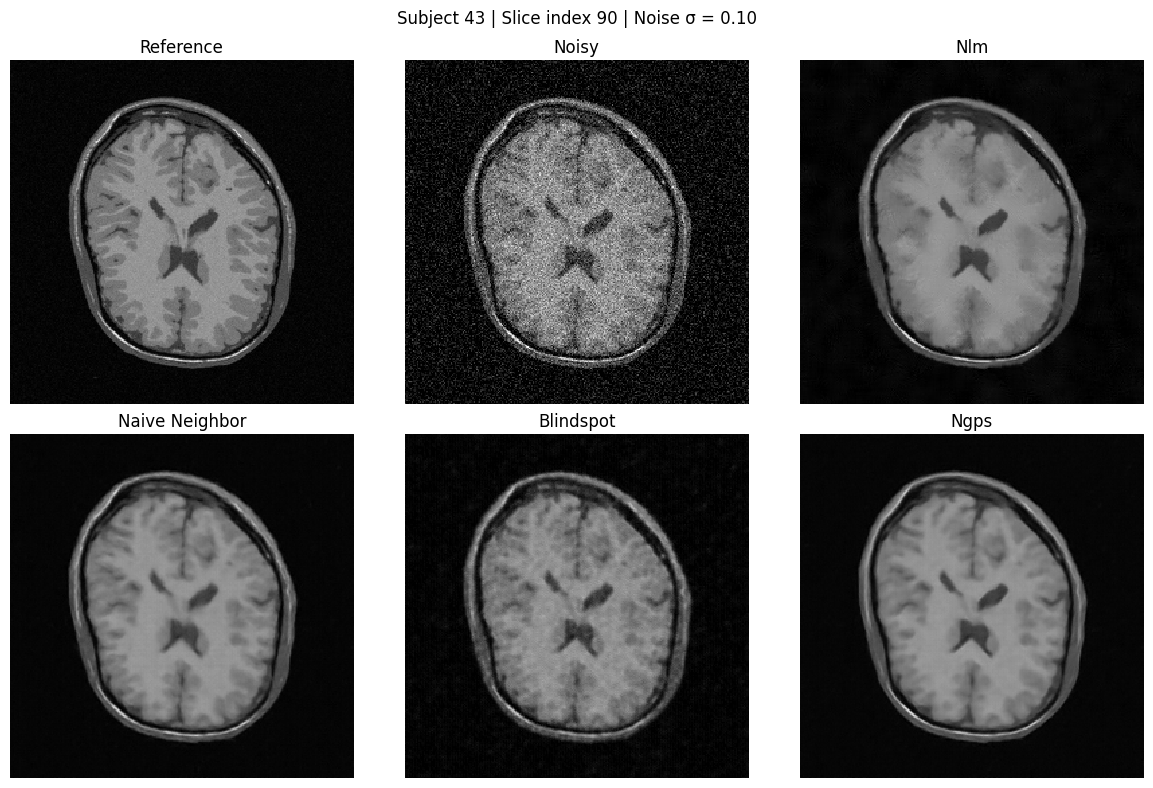

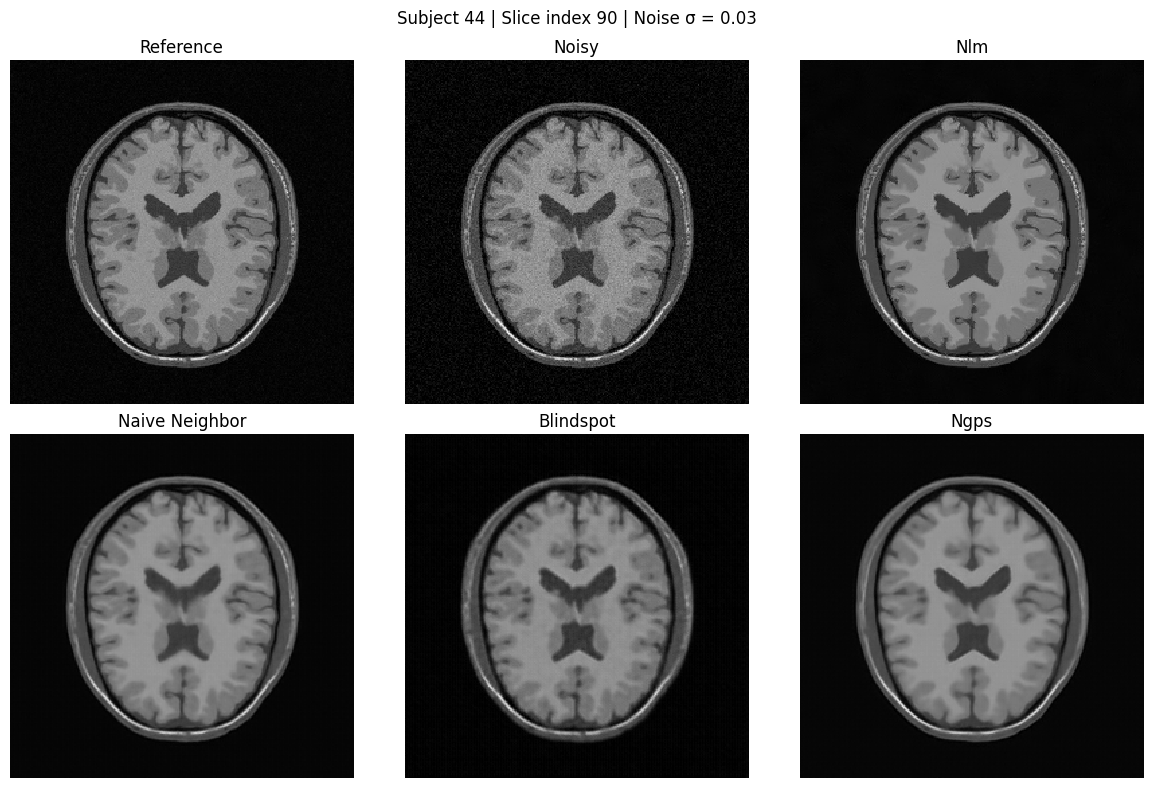

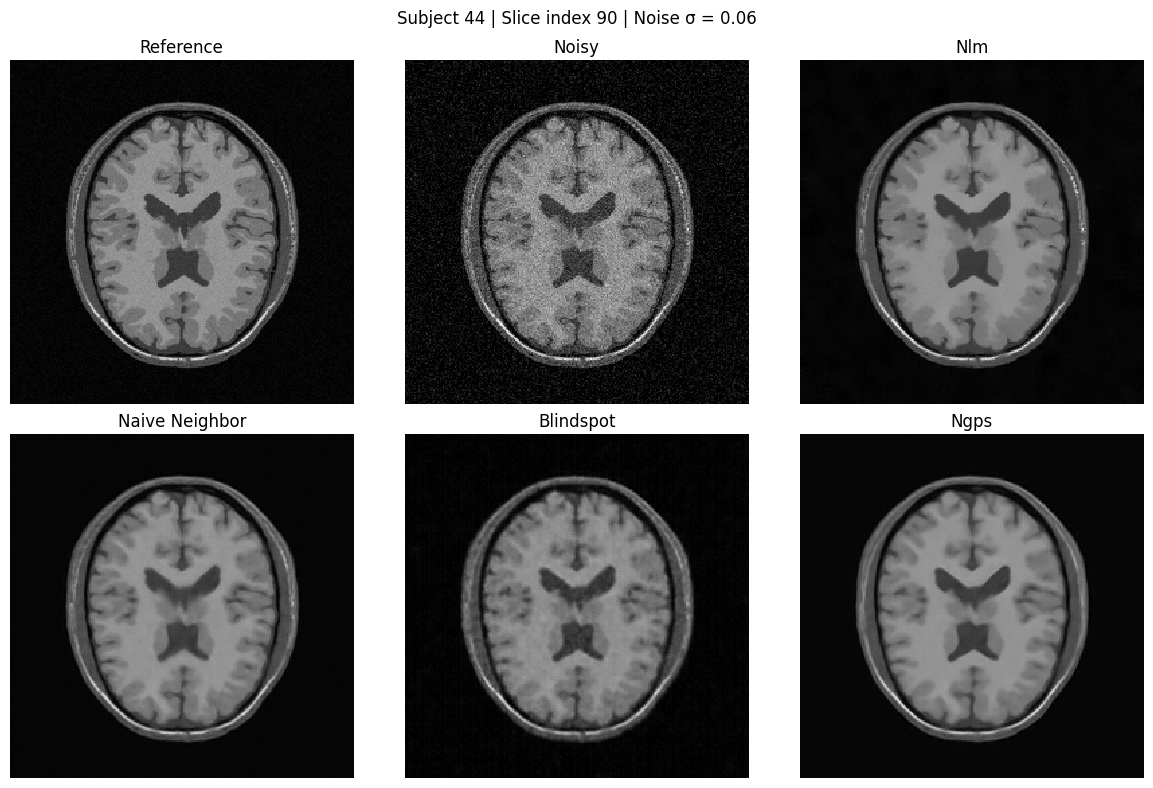

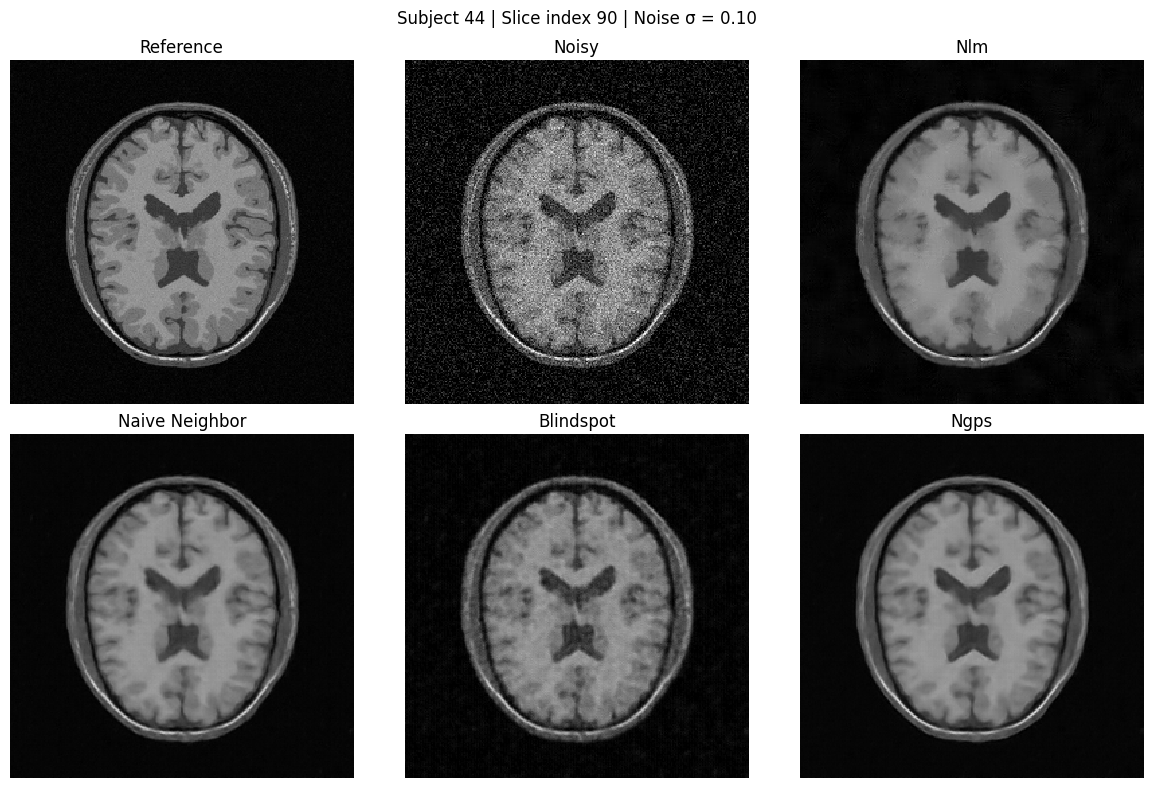

Six comparison figures saved to: /content/drive/MyDrive/T3_MRI_Denoising/results/figures


In [21]:
import matplotlib.pyplot as plt
import numpy as np

figure_dir = PROJECT_DIR / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

slice_index = 90  # Fixed middle slice, zero-based indexing.

for subject in ["43", "44"]:
    reference = np.load(
        PROJECT_DIR / f"scoring_only/references/subject{subject}.npy"
    )

    for sigma in [0.03, 0.06, 0.10]:
        noisy = np.load(
            PROJECT_DIR /
            f"data/noisy/sigma_{sigma:.2f}/test/subject{subject}.npy"
        )

        images = {"Reference": reference, "Noisy": noisy}

        for method in ["NLM", "naive_neighbor", "blindspot", "NGPS"]:
            images[method] = np.load(
                PROJECT_DIR /
                f"results/predictions/{method}/sigma_{sigma:.2f}/subject{subject}.npy"
            )

        fig, axes = plt.subplots(2, 3, figsize=(12, 8))

        for ax, (name, volume) in zip(axes.flat, images.items()):
            ax.imshow(
                volume[slice_index],
                cmap="gray", vmin=0, vmax=1,
                interpolation="nearest"
            )
            ax.set_title(name.replace("_", " ").title())
            ax.axis("off")

        fig.suptitle(
            f"Subject {subject} | Slice index {slice_index} | "
            f"Noise σ = {sigma:.2f}"
        )
        fig.tight_layout()

        filename = figure_dir / f"subject{subject}_sigma{sigma:.2f}.png"
        fig.savefig(filename, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)

print("Six comparison figures saved to:", figure_dir)

All methods reduce visible noise, but noise removal can also blur fine structures. NLM performs best overall numerically, while NGPS outperforms NLM at the highest noise level. NGPS does not outperform naive-neighbor overall in our experiment.

In [23]:
from google.colab import drive
from pathlib import Path
import subprocess
import sys
import importlib

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/T3_MRI_Denoising")
CODE_DIR = Path("/content/NGPS")

if not (CODE_DIR / ".git").exists():
    subprocess.run(
        ["git", "clone", "https://github.com/cv-cho/NGPS.git", str(CODE_DIR)],
        check=True
    )

# Use the same source version as your experiment.
subprocess.run(
    ["git", "-C", str(CODE_DIR), "checkout",
     "c04331d56ad6c5c8b9ea510f77359b154db57ebe"],
    check=True
)

# Restore your saved loader modification.
import shutil
saved_loader = PROJECT_DIR / "code_changes/datasets/volume_folder.py"
if saved_loader.exists():
    shutil.copy2(saved_loader, CODE_DIR / "datasets/volume_folder.py")

sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()

from ngps import build_nafnet, load_config
print("NGPS imported successfully. Ready to load your saved model.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NGPS imported successfully. Ready to load your saved model.


Loaded final NGPS-trained NAFNet checkpoint.
Device: cuda
Test subject: 43 | Slice: 90 | Noise σ: 0.1
New denoised prediction generated.

Single-slice metrics:
Noisy input: PSNR = 19.97 dB | SSIM = 0.2789
NGPS output: PSNR = 31.00 dB | SSIM = 0.8368


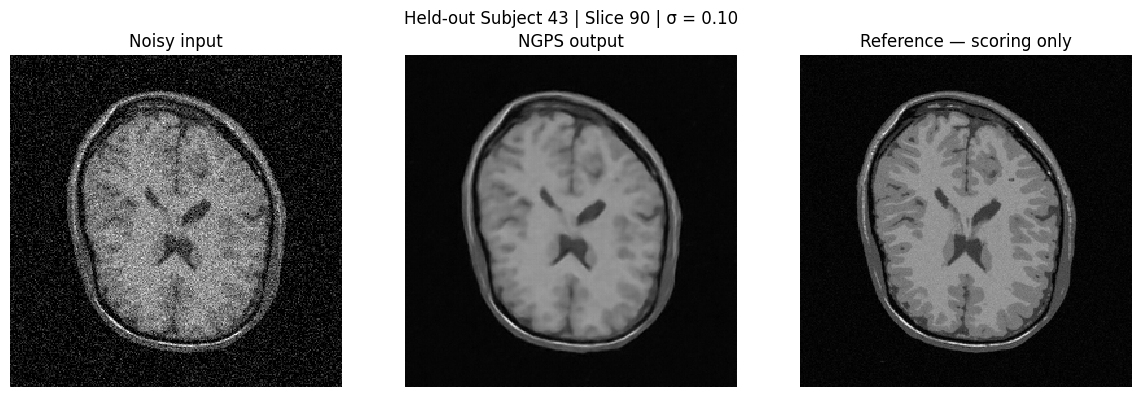

In [25]:
from pathlib import Path
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

PROJECT_DIR = Path("/content/drive/MyDrive/T3_MRI_Denoising")
sys.path.insert(0, "/content/NGPS")

from ngps import build_nafnet, load_config

subject = "43"
sigma = 0.10
slice_index = 90
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Load the frozen model.
checkpoint_path = PROJECT_DIR / "runs/ngps_combined/model_final.pth"
config_path = PROJECT_DIR / "configs/course_training.yaml"

cfg, _, _ = load_config(str(config_path))
model = build_nafnet(cfg).to(device)

checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=True
)
model.load_state_dict(checkpoint["model"])
model.eval()

print("Loaded final NGPS-trained NAFNet checkpoint.")
print(f"Device: {device}")
print(f"Test subject: {subject} | Slice: {slice_index} | Noise σ: {sigma}")

# 2. Generate a new prediction using ONLY the noisy input.
noisy_path = PROJECT_DIR / (
    f"data/noisy/sigma_{sigma:.2f}/test/subject{subject}.npy"
)
noisy = np.load(noisy_path)[slice_index]

tensor = torch.from_numpy(noisy)[None, None].to(device)

with torch.inference_mode():
    denoised = model(tensor).clamp(0, 1).cpu().numpy()[0, 0]

print("New denoised prediction generated.")

# 3. Load the reference AFTER inference, for scoring only.
reference_path = PROJECT_DIR / (
    f"scoring_only/references/subject{subject}.npy"
)
reference = np.load(reference_path)[slice_index]

print("\nSingle-slice metrics:")
for name, image in [("Noisy input", noisy), ("NGPS output", denoised)]:
    psnr = peak_signal_noise_ratio(reference, image, data_range=1)
    ssim = structural_similarity(
        reference, image, data_range=1, win_size=7
    )
    print(f"{name}: PSNR = {psnr:.2f} dB | SSIM = {ssim:.4f}")

# 4. Display all images using the same brightness scale.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, title, image in zip(
    axes,
    ["Noisy input", "NGPS output", "Reference — scoring only"],
    [noisy, denoised, reference]
):
    ax.imshow(
        image, cmap="gray", vmin=0, vmax=1,
        interpolation="nearest"
    )
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"Held-out Subject {subject} | Slice {slice_index} | σ = {sigma:.2f}"
)
plt.tight_layout()
plt.show()